# Bootstrap sensitivity analysis 
- input: final dataframes for ICON full (62_)
- test sensitivity of bootstrap to block length and nboot (then applied in nbooks/70)
- output: plot of sensitivity analysis

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

from pathlib import Path
import os

import sys
import pandas as pd 
import xarray as xr

sys.path.append("../tools")

import defs_application

import pickle

from cell_props import compute_annual_cell_stats # function for the annual stats


In [2]:
inputdir = Path("../output/final_dataframes/FULL")

datasets = ["cell_tracks", "anvil_features", "domain"]
blocks_to_test = [1,3,7, 14,21,28,35,42,49,56,63,70,77]
boots_to_test = [100, 500, 1000,1500]

sensitivity_and_plot_dir = Path("../output/annual/sensitivity")
sensitivity_and_plot_dir.mkdir(parents=True, exist_ok=True)

sensitivity_cache_path = Path(sensitivity_and_plot_dir)/f"sensitivity_block_boot.pkl"

if os.path.exists(sensitivity_cache_path):
    with open(sensitivity_cache_path, "rb") as f:
        sensitivity = pickle.load(f)
    print(f"Loaded cached sensitivity object from {sensitivity_cache_path}")
else:
    sensitivity = {}
    years = ["2021"]
    for dataset in datasets:
        data = {}
        for year in years:
            data[year] = pd.read_hdf(os.path.join(inputdir, f"{dataset}_ICON_{year}.h5"), key="table")

        sensitivity[dataset] = {}
        for block in blocks_to_test:
            sensitivity[dataset][block] = {}
            for n_boot in boots_to_test:
                sensitivity[dataset][block][n_boot] = compute_annual_cell_stats(data, block_length_days=block, n_boot=n_boot)

    with open(sensitivity_cache_path, "wb") as f:
        pickle.dump(sensitivity, f)
    print(f"Computed and cached sensitivity object to {sensitivity_cache_path}")

Loaded cached sensitivity object from ../output/annual/sensitivity/sensitivity_block_boot.pkl


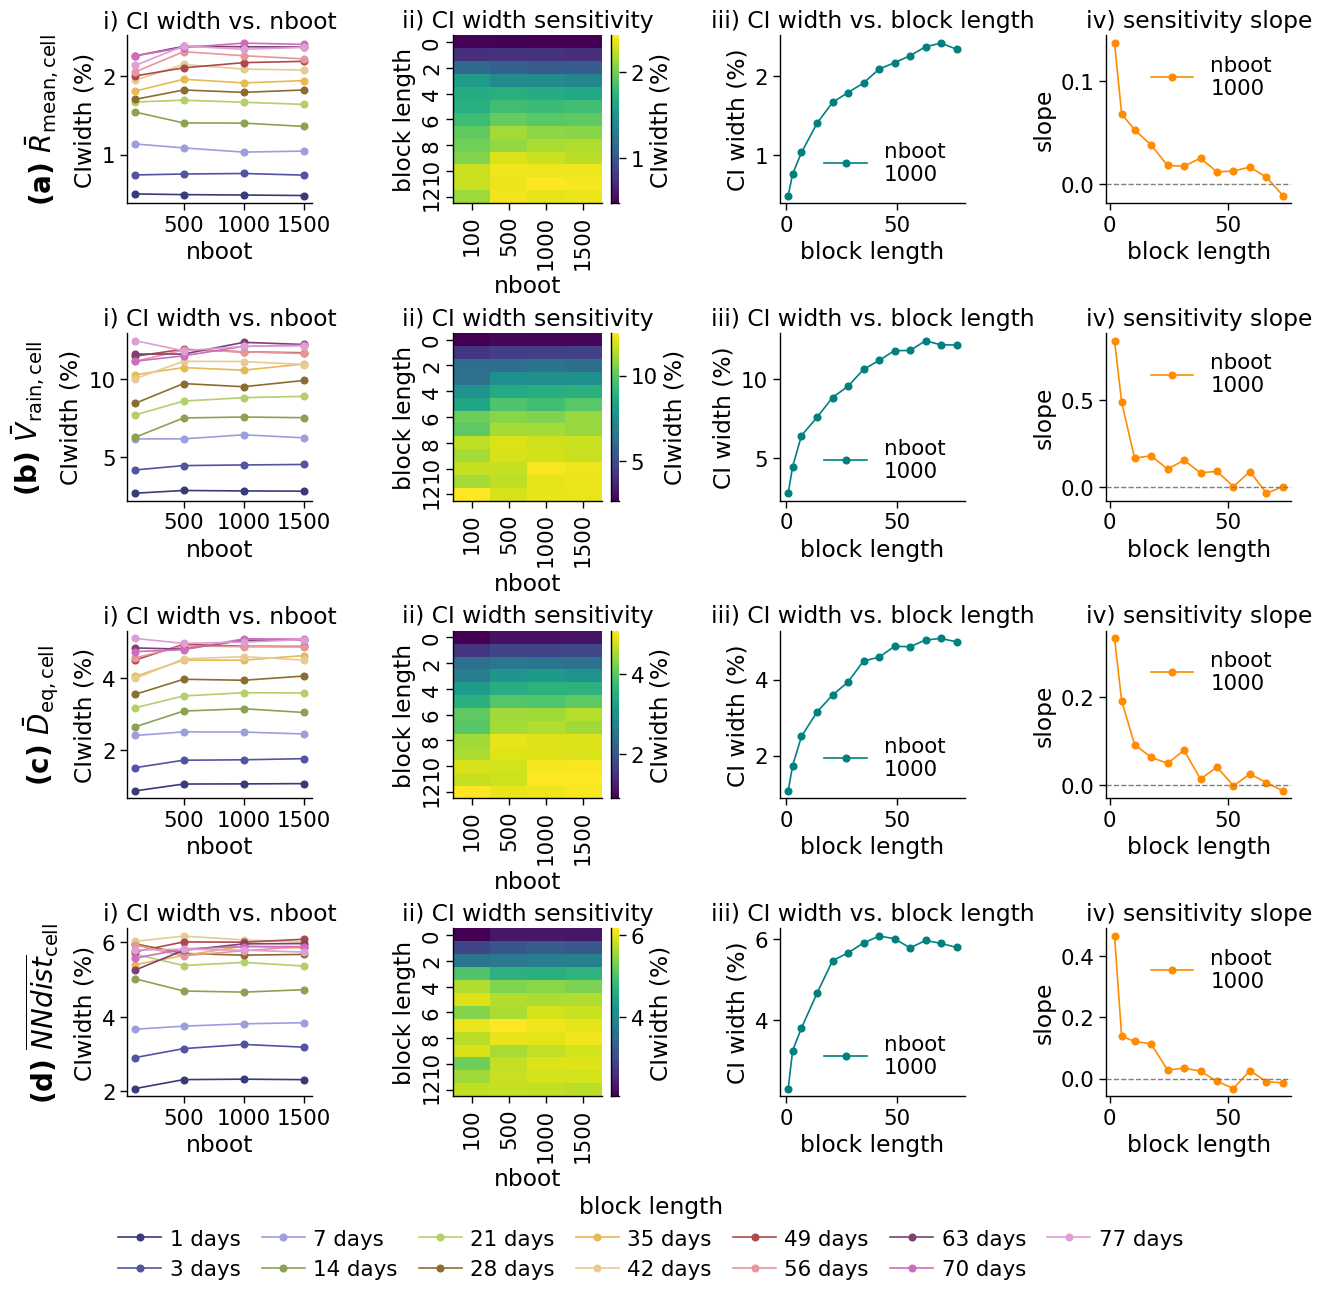

In [17]:
variables = defs_application.var_order_tracks_cellonly
variables = ['mean_precip_cell_mean',
 #'max_precip_cell_max',
 'rain_volume_cell_mean',
 'd_eq_cell_mean',
 'min_dist_cell_km_mean',
 #'n_sister_cells_mean',
# 'mean_iwp_cell_mean',
 # 'lifetime_cell',
 # 'velo_cell_mean',
            #  "PE_cell",
            # "PE_anvil"
            ]
dataset = "cell_tracks"
VAR_META_ICON = defs_application.make_var_meta(variables, source="ICON")


n_boot_fixed = 1000  # already shown to be converged for most variables

cmap_blocks = matplotlib.colormaps["tab20b"].resampled(len(blocks_to_test))
sns.set_context("paper", font_scale = 1.75)
fig, axes = plt.subplots(len(variables), 4, figsize=(13, 3* len(variables)))

for row, var in enumerate(variables):
    ax_line, ax_heat, ax_width, ax_slope = axes[row]

    #  Panel 1 
    for i, block in enumerate(blocks_to_test):
        rel_widths = []
        for n_boot in boots_to_test:
            ds = sensitivity[dataset][block][n_boot]
            width = (ds["ci_high"][var] - ds["ci_low"][var]).values
            mean = np.abs(ds["mean"][var].values)
            rel_widths.append(np.nanmean(width / mean) * 100)
        ax_line.plot(boots_to_test, rel_widths, marker="o", color=cmap_blocks(i), label=f"{block} days")
    ax_line.set_xlabel("nboot")
    ax_line.set_ylabel("CIwidth (%)")
    ax_line.set_title("i) CI width vs. nboot")

    #  Panel 2 
    grid = np.zeros((len(blocks_to_test), len(boots_to_test)))
    for i, block in enumerate(blocks_to_test):
        for j, n_boot in enumerate(boots_to_test):
            ds = sensitivity[dataset][block][n_boot]
            width = (ds["ci_high"][var] - ds["ci_low"][var]).values
            mean = np.abs(ds["mean"][var].values)
            grid[i, j] = np.nanmean(width / mean) * 100
    sns.heatmap(
        grid, ax=ax_heat, cmap="viridis", annot=False, fmt=".2f",
        xticklabels=boots_to_test, yticklabels=2 #yticklabels=[f"{b}d" for b in blocks_to_test]
        ,
        cbar_kws={"label": "CIwidth (%)"},
    )
    ax_heat.set_xlabel("nboot")
    ax_heat.set_ylabel("block length")
    ax_heat.set_title("ii) CI width sensitivity")

    #  Panel 3 
    widths = []
    for block in blocks_to_test:
        ds = sensitivity[dataset][block][n_boot_fixed]
        w = (ds["ci_high"][var] - ds["ci_low"][var]).values
        m = np.abs(ds["mean"][var].values)
        widths.append(np.nanmean(w / m) * 100)
    widths = np.array(widths)
    blocks = np.array(blocks_to_test)

    ax_width.plot(blocks, widths, marker="o", color="teal", label = f"nboot\n{n_boot_fixed}")
    ax_width.set_xlabel("block length")
    ax_width.set_ylabel("CI width (%)")
    ax_width.set_title("iii) CI width vs. block length")
    ax_width.legend(loc="lower right", frameon= False)

    #  Panel 4 
    slopes = np.diff(widths) / np.diff(blocks)
    midpoints = (blocks[1:] + blocks[:-1]) / 2
    ax_slope.plot(midpoints, slopes, marker="o", color="darkorange", label = f"nboot\n{n_boot_fixed}")
    ax_slope.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax_slope.set_xlabel("block length")
    ax_slope.set_ylabel("slope")
    ax_slope.set_title("iv) sensitivity slope")
    ax_slope.legend(loc="upper right",frameon = False)

    #  Row title 
    letter = chr(ord('a') + row) 
    label = VAR_META_ICON[var]["label"]
    
    ax_line.annotate(
        f"({letter}) {label}", xy=(0, 0.5), xytext=(-ax_line.yaxis.labelpad - 5, 0),
        xycoords=ax_line.yaxis.label, textcoords="offset points",
        size=20, ha="right", va="center", weight="bold", rotation=90,
    )

    


handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.02),      # directly under the figure edge
           frameon=False,
           title="block length",
           ncol=int(np.ceil(len(blocks_to_test) / 2)),
           handletextpad=0.4, columnspacing=1.0)


plt.tight_layout(pad=0.4)      # smaller outer padding
sns.despine()

plt.savefig(f"../output/plots/{dataset}_sensit.pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()

# plot

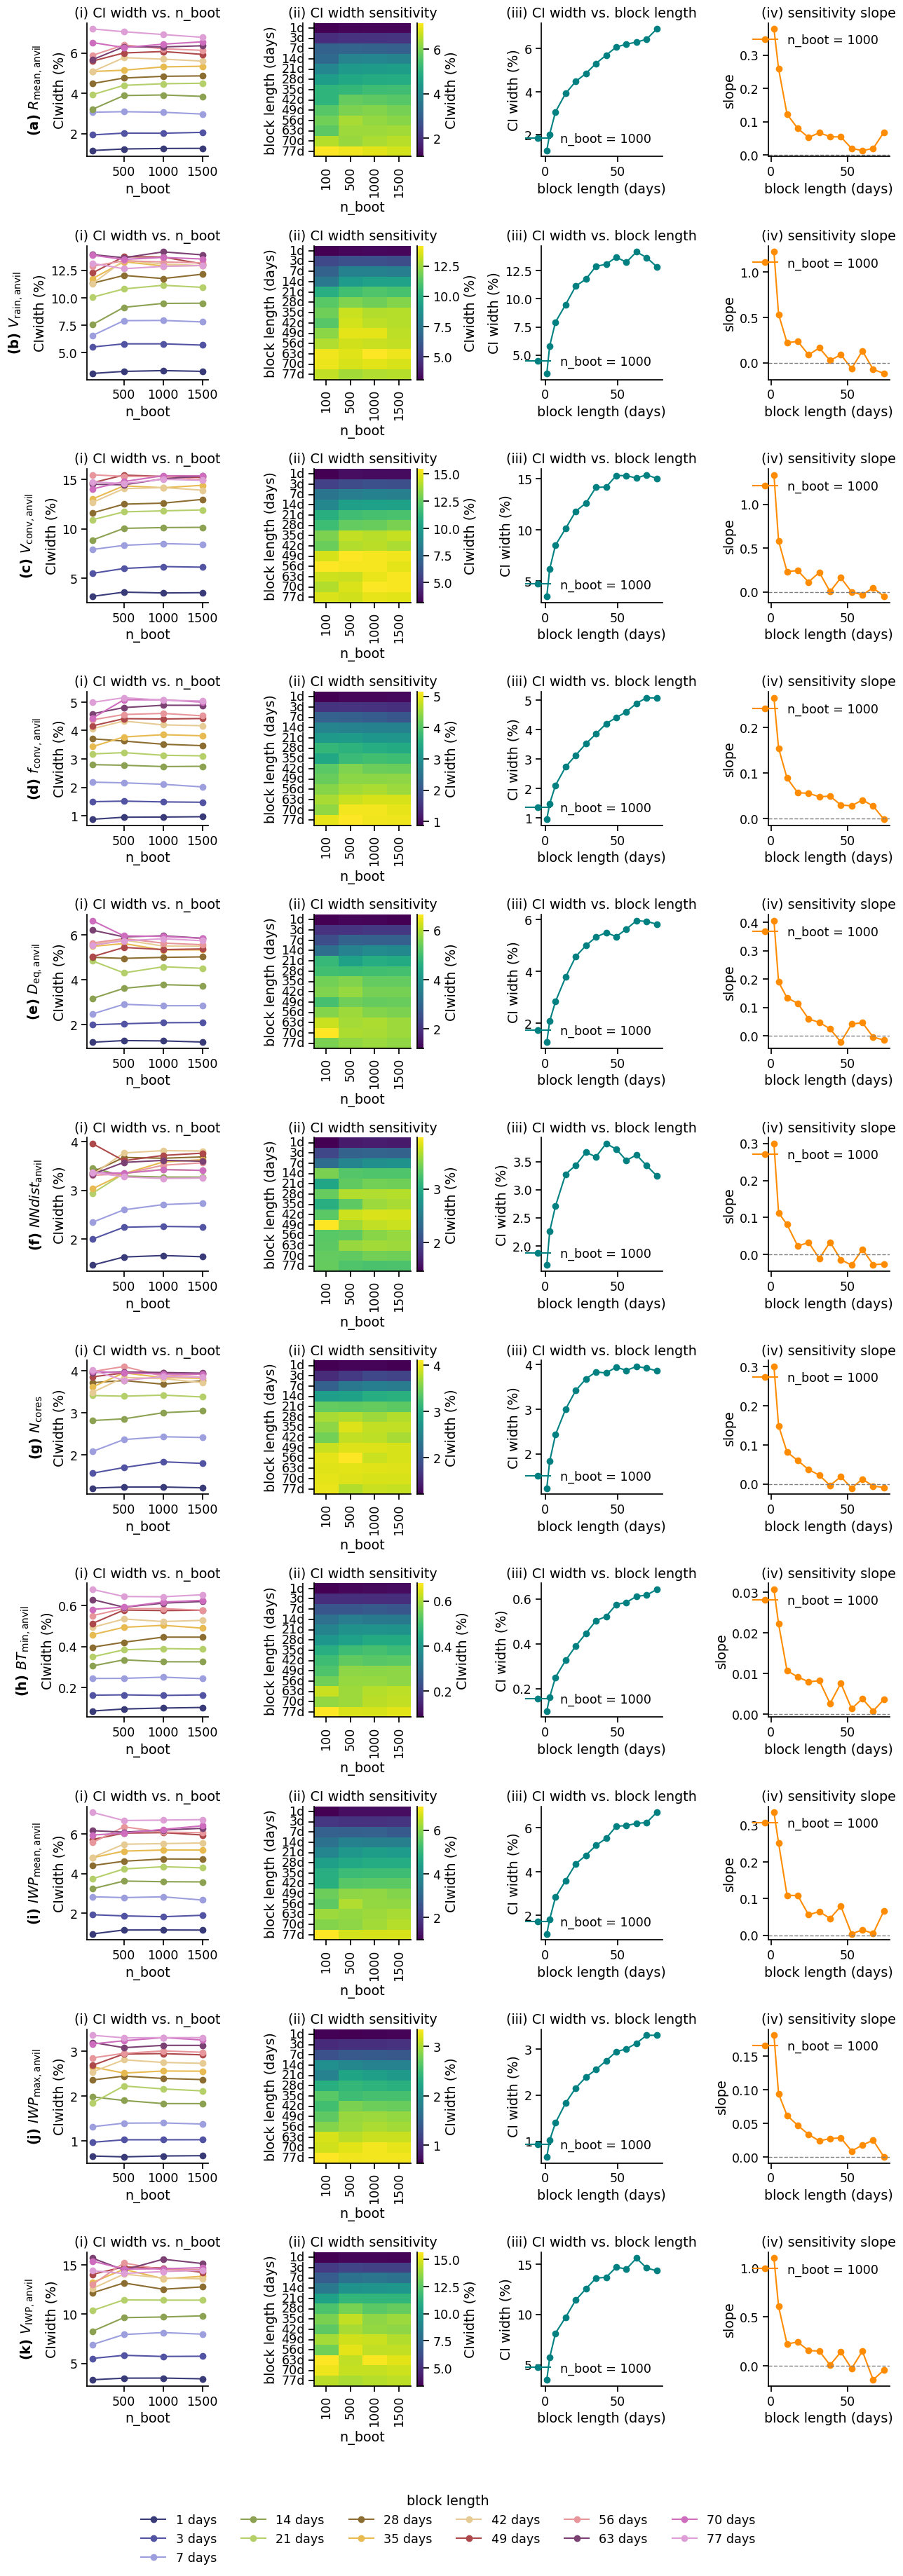

In [4]:
variables=[
    'mean_precip_anvil',
    'rain_volume_anvil',
    'convective_rain_volume_anvil',
    'fraction_convection_rain_volume_anvil',
      'd_eq_anvil',
    "min_dist_anvil_km",
     'n_children_anvil',
       'min_tb_anvil',
    'mean_iwp_anvil',
    'max_iwp_anvil', 
    'iwp_volume_anvil',
]
   
dataset = "anvil_features"
VAR_META_ICON = defs_application.make_var_meta(variables, source="ICON")


n_boot_fixed = 1000  # already shown to be converged for most variables

cmap_blocks = matplotlib.colormaps["tab20b"].resampled(len(blocks_to_test))
sns.set_context("notebook", font_scale = 1.15)
fig, axes = plt.subplots(len(variables), 4, figsize=(13, 3.2* len(variables)))

for row, var in enumerate(variables):
    ax_line, ax_heat, ax_width, ax_slope = axes[row]

    #  Panel 1 
    for i, block in enumerate(blocks_to_test):
        rel_widths = []
        for n_boot in boots_to_test:
            ds = sensitivity[dataset][block][n_boot]
            width = (ds["ci_high"][var] - ds["ci_low"][var]).values
            mean = np.abs(ds["mean"][var].values)
            rel_widths.append(np.nanmean(width / mean) * 100)
        ax_line.plot(boots_to_test, rel_widths, marker="o", color=cmap_blocks(i), label=f"{block} days")
    ax_line.set_xlabel("n_boot")
    ax_line.set_ylabel("CIwidth (%)")
    ax_line.set_title("(i) CI width vs. n_boot")

    #  Panel 2 
    grid = np.zeros((len(blocks_to_test), len(boots_to_test)))
    for i, block in enumerate(blocks_to_test):
        for j, n_boot in enumerate(boots_to_test):
            ds = sensitivity[dataset][block][n_boot]
            width = (ds["ci_high"][var] - ds["ci_low"][var]).values
            mean = np.abs(ds["mean"][var].values)
            grid[i, j] = np.nanmean(width / mean) * 100
    sns.heatmap(
        grid, ax=ax_heat, cmap="viridis", annot=False, fmt=".2f",
        xticklabels=boots_to_test, yticklabels=[f"{b}d" for b in blocks_to_test],
        cbar_kws={"label": "CIwidth (%)"},
    )
    ax_heat.set_xlabel("n_boot")
    ax_heat.set_ylabel("block length (days)")
    ax_heat.set_title("(ii) CI width sensitivity")

    #  Panel 3 
    widths = []
    for block in blocks_to_test:
        ds = sensitivity[dataset][block][n_boot_fixed]
        w = (ds["ci_high"][var] - ds["ci_low"][var]).values
        m = np.abs(ds["mean"][var].values)
        widths.append(np.nanmean(w / m) * 100)
    widths = np.array(widths)
    blocks = np.array(blocks_to_test)

    ax_width.plot(blocks, widths, marker="o", color="teal", label = f"n_boot = {n_boot_fixed}")
    ax_width.set_xlabel("block length (days)")
    ax_width.set_ylabel("CI width (%)")
    ax_width.set_title("(iii) CI width vs. block length")
    ax_width.legend(loc="lower right", frameon= False)

    #  Panel 4 
    slopes = np.diff(widths) / np.diff(blocks)
    midpoints = (blocks[1:] + blocks[:-1]) / 2
    ax_slope.plot(midpoints, slopes, marker="o", color="darkorange", label = f"n_boot = {n_boot_fixed}")
    ax_slope.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax_slope.set_xlabel("block length (days)")
    ax_slope.set_ylabel("slope")
    ax_slope.set_title("(iv) sensitivity slope")
    ax_slope.legend(loc="upper right",frameon = False)

    #  Row title 
    letter = chr(ord('a') + row) 
    label = VAR_META_ICON[var]["label"]
    
    ax_line.annotate(
        f"({letter}) {label}", xy=(0, 0.5), xytext=(-ax_line.yaxis.labelpad - 5, 0),
        xycoords=ax_line.yaxis.label, textcoords="offset points",
        size=14, ha="right", va="center", weight="bold", rotation=90,
    )

    
    
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.01),
           frameon=False, title="block length", ncol=len(blocks_to_test)/2)

plt.tight_layout()
sns.despine()
plt.savefig(f"../output/plots/{dataset}_sensit.pdf", bbox_inches="tight")
plt.show()